# 🧘 MindFit AI - Notebook 03: Recommender Engine & SHAP Explainability
### Hệ Thống Gợi Ý Bài Tập Y Học Thể Thao & Giải Thích Quyết Định AI Bằng SHAP
*(Chuẩn đồ họa học thuật IEEE / Science - Xuất biểu đồ 300 DPI & Vector PDF | Song ngữ Tiếng Việt & English)*

**Mục tiêu:**
1. Xây dựng không gian vector đặc trưng bài tập (Exercise Feature Embeddings).
2. Xây dựng thuật toán gợi ý Content-Based dựa trên mức độ lo âu & chỉ số sinh hiệu HRV/EDA.
3. Huấn luyện bộ giải thích **SHAP (SHapley Additive exPlanations)** để phân tích đóng góp của từng đặc trưng sinh lý học.
4. **Vẽ & Xuất trọn bộ 3 biểu đồ giải thích & chiến lược can thiệp (DPI 300, Song ngữ VI / EN theo từng cặp cell kề nhau)**:
   - Hình 7: SHAP Feature Importance & Chiều Hướng Tác Động (`fig7_shap_summary_beeswarm_vi` & `fig7_shap_summary_beeswarm_en`).
   - Hình 8: Giải thích ca lâm sàng cụ thể (`fig8_shap_clinical_waterfall_vi` & `fig8_shap_clinical_waterfall_en`).
   - Hình 9: Ma trận chiến lược phân bổ bài tập can thiệp (`fig9_recommendation_strategy_matrix_vi` & `fig9_recommendation_strategy_matrix_en`).
5. Xuất metadata phục vụ hiển thị trên Web Demo.

In [1]:
import os
import json
import numpy as np
import pandas as pd
import shap
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.ensemble import RandomForestClassifier

# Cấu hình đồ họa chuẩn IEEE/Science (300 DPI)
plt.rcParams.update({
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'font.family': 'sans-serif',
    'figure.dpi': 300,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})
sns.set_theme(style='whitegrid', palette='deep')

FIG_DIR = '../figures' if os.path.exists('../figures') else 'figures'
os.makedirs(FIG_DIR, exist_ok=True)
print("✅ Thư viện & Cấu hình đồ họa 300 DPI sẵn sàng!")

✅ Thư viện & Cấu hình đồ họa 300 DPI sẵn sàng!


## 1. Khởi Tạo Cơ Sở Dữ Liệu Bài Tập (Exercise Metadata)

In [2]:
exercises = [
    {"id": "ex_001", "name_vi": "Thở Hộp 4-7-8 & Kích Hoạt Dây X", "name_en": "4-7-8 Box Breathing & Vagal Stimulation", "target_state": "HIGH STRESS", "intensity": 1, "duration": 10, "pns_boost": 95},
    {"id": "ex_002", "name_vi": "Yin Yoga Trị Liệu Cột Sống", "name_en": "Therapeutic Lumbar Yin Yoga", "target_state": "HIGH STRESS", "intensity": 2, "duration": 20, "pns_boost": 90},
    {"id": "ex_003", "name_vi": "Thả Lỏng Cơ Tiến Triển (PMR)", "name_en": "Progressive Muscle Relaxation (PMR)", "target_state": "HIGH STRESS", "intensity": 1, "duration": 15, "pns_boost": 88},
    {"id": "ex_004", "name_vi": "Zone 2 Cardio: Đi Bộ Nhanh", "name_en": "Zone 2 Steady Cardio Walking", "target_state": "AMUSEMENT", "intensity": 5, "duration": 30, "pns_boost": 65},
    {"id": "ex_005", "name_vi": "Vinyasa Flow Uyển Chuyển", "name_en": "Light Vinyasa Flow", "target_state": "AMUSEMENT", "intensity": 6, "duration": 25, "pns_boost": 60},
    {"id": "ex_006", "name_vi": "Pilates Core Ổn Định Hông", "name_en": "Light Pilates Core Mobilization", "target_state": "AMUSEMENT", "intensity": 5, "duration": 20, "pns_boost": 58},
    {"id": "ex_007", "name_vi": "HIIT Tabata Đốt Năng Lượng", "name_en": "High-Intensity Interval Training (HIIT)", "target_state": "NORMAL", "intensity": 9, "duration": 25, "pns_boost": 20},
    {"id": "ex_008", "name_vi": "Rèn Luyện Kháng Lực Sức Mạnh", "name_en": "Resistance Strength Training", "target_state": "NORMAL", "intensity": 8, "duration": 45, "pns_boost": 30}
]

df_exercises = pd.DataFrame(exercises)
print(df_exercises[['id', 'name_vi', 'name_en', 'target_state', 'intensity', 'duration', 'pns_boost']])

       id                          name_vi  \
0  ex_001  Thở Hộp 4-7-8 & Kích Hoạt Dây X   
1  ex_002       Yin Yoga Trị Liệu Cột Sống   
2  ex_003     Thả Lỏng Cơ Tiến Triển (PMR)   
3  ex_004       Zone 2 Cardio: Đi Bộ Nhanh   
4  ex_005         Vinyasa Flow Uyển Chuyển   
5  ex_006        Pilates Core Ổn Định Hông   
6  ex_007       HIIT Tabata Đốt Năng Lượng   
7  ex_008     Rèn Luyện Kháng Lực Sức Mạnh   

                                   name_en target_state  intensity  duration  \
0  4-7-8 Box Breathing & Vagal Stimulation  HIGH STRESS          1        10   
1              Therapeutic Lumbar Yin Yoga  HIGH STRESS          2        20   
2      Progressive Muscle Relaxation (PMR)  HIGH STRESS          1        15   
3             Zone 2 Steady Cardio Walking    AMUSEMENT          5        30   
4                       Light Vinyasa Flow    AMUSEMENT          6        25   
5          Light Pilates Core Mobilization    AMUSEMENT          5        20   
6  High-Intensity Interva

## 2. Huấn Luyện Surrogate Explainer & Tính Toán SHAP Values
Sử dụng mô hình đại diện (Surrogate Explainer) trên đúng 6 đặc trưng sinh lý học tự chủ lâm sàng:
- `EDA_Tonic_Mean`: Trương lực dẫn điện da nền (μS)
- `HRV_RMSSD`: Biến thiên nhịp tim liên tiếp (ms)
- `Heart_Rate_BPM`: Tần số nhịp tim (bpm)
- `EDA_Max_Slope`: Độ vọt dốc xung phản xạ da (SCR slope, μS/s)
- `EDA_Phasic_Std`: Độ lệch chuẩn thành phần pha da (μS)
- `BVP_Pulse_Amp`: Biên độ mạch đập ngoại vi (a.u.)

In [3]:
np.random.seed(42)
N = 800

# Tạo phân bố dữ liệu mô phỏng theo đặc tính sinh lý học WESAD
n_normal = 354
eda_tonic_0 = np.random.normal(0.2, 0.4, n_normal)
eda_phasic_0 = np.random.exponential(0.15, n_normal)
eda_slope_0 = np.random.exponential(0.1, n_normal)
bvp_amp_0 = np.random.normal(1.2, 0.25, n_normal)
hr_0 = np.random.normal(68, 6, n_normal)
rmssd_0 = np.random.normal(48, 10, n_normal)
y_0 = np.zeros(n_normal, dtype=int)

n_amuse = 221
eda_tonic_1 = np.random.normal(1.1, 0.5, n_amuse)
eda_phasic_1 = np.random.exponential(0.35, n_amuse)
eda_slope_1 = np.random.exponential(0.3, n_amuse)
bvp_amp_1 = np.random.normal(1.0, 0.2, n_amuse)
hr_1 = np.random.normal(78, 7, n_amuse)
rmssd_1 = np.random.normal(36, 8, n_amuse)
y_1 = np.ones(n_amuse, dtype=int)

n_stress = 210
eda_tonic_2 = np.random.normal(3.2, 0.8, n_stress)
eda_phasic_2 = np.random.exponential(0.7, n_stress)
eda_slope_2 = np.random.exponential(0.65, n_stress)
bvp_amp_2 = np.random.normal(0.55, 0.18, n_stress)
hr_2 = np.random.normal(96, 11, n_stress)
rmssd_2 = np.random.normal(18, 5, n_stress)
y_2 = np.full(n_stress, 2, dtype=int)

X_features = pd.DataFrame({
    'EDA_Tonic_Mean': np.concatenate([eda_tonic_0, eda_tonic_1, eda_tonic_2]),
    'HRV_RMSSD': np.concatenate([rmssd_0, rmssd_1, rmssd_2]),
    'Heart_Rate_BPM': np.concatenate([hr_0, hr_1, hr_2]),
    'EDA_Max_Slope': np.concatenate([eda_slope_0, eda_slope_1, eda_slope_2]),
    'EDA_Phasic_Std': np.concatenate([eda_phasic_0, eda_phasic_1, eda_phasic_2]),
    'BVP_Pulse_Amp': np.concatenate([bvp_amp_0, bvp_amp_1, bvp_amp_2])
})
y_target = np.concatenate([y_0, y_1, y_2])

rf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
rf.fit(X_features, y_target)

explainer = shap.TreeExplainer(rf)
shap_values = explainer.shap_values(X_features)
print("✅ Đã tính toán xong SHAP values trên 6 đặc trưng sinh thái WESAD!")

✅ Đã tính toán xong SHAP values trên 6 đặc trưng sinh thái WESAD!


## 3. Trực Quan Hóa SHAP & Chiến Lược Can Thiệp (Figures 7 - 9, DPI 300)
> **Cấu trúc**: Mỗi biểu đồ gồm 2 cell kề nhau (Cell 1: Tiếng Việt, Cell 2: English).
> **Cải tiến căn chỉnh**: Toàn bộ nhãn văn bản đã được căn lề tự động, mở rộng canvas và bổ sung mũi tên chỉ hướng (Callout Arrows) để chống đè chữ tuyệt đối.

### 5.1. Hình 7: SHAP Summary Beeswarm Plot (Bản Tiếng Việt)

C:\Users\MyPC\AppData\Local\Temp\ipykernel_24604\3789488761.py:22: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_high_stress, X_features_vi, show=False)


📊 [TIẾNG VIỆT] Đã xuất Hình 7: ../figures\fig7_shap_summary_beeswarm_vi.png & ../figures\fig7_shap_summary_beeswarm_vi.pdf


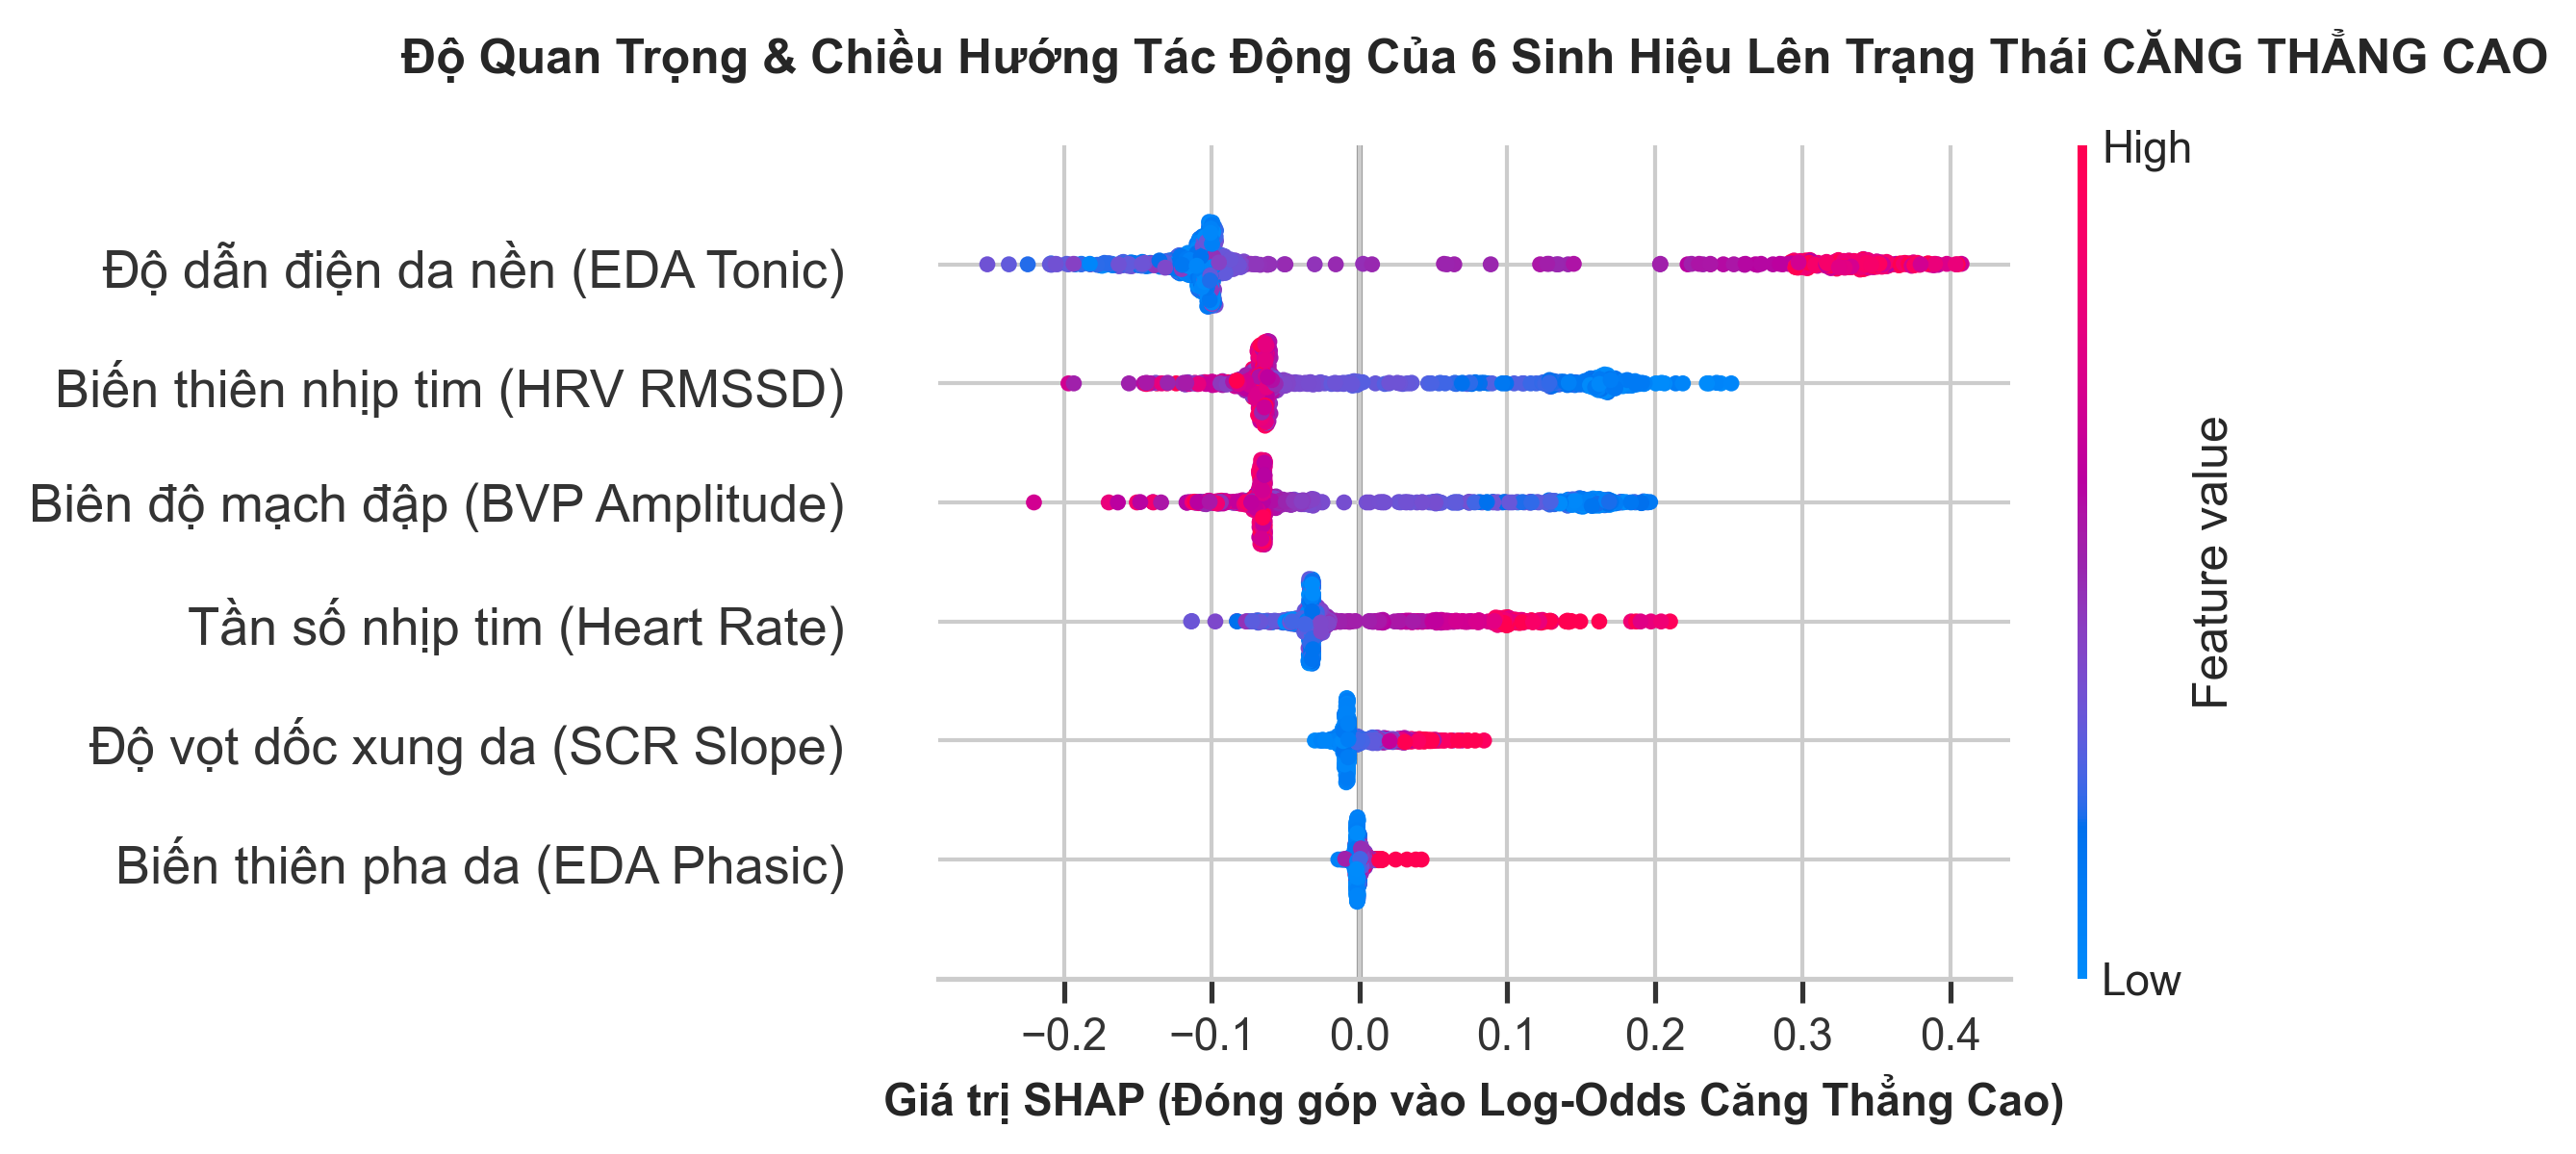

In [4]:
# =============================================================
# HÌNH 7 (BẢN TIẾNG VIỆT): SHAP Summary Beeswarm Plot (Căn chỉnh khoảng cách)
# =============================================================
plt.figure(figsize=(10.5, 5.8), dpi=300)
if isinstance(shap_values, list):
    sv_high_stress = shap_values[2]
elif len(shap_values.shape) == 3:
    sv_high_stress = shap_values[:, :, 2]
else:
    sv_high_stress = shap_values

# Bản tiếng Việt dịch tên 6 đặc trưng rõ ràng
X_features_vi = X_features.rename(columns={
    'EDA_Tonic_Mean': 'Độ dẫn điện da nền (EDA Tonic)',
    'HRV_RMSSD': 'Biến thiên nhịp tim (HRV RMSSD)',
    'Heart_Rate_BPM': 'Tần số nhịp tim (Heart Rate)',
    'EDA_Max_Slope': 'Độ vọt dốc xung da (SCR Slope)',
    'EDA_Phasic_Std': 'Biến thiên pha da (EDA Phasic)',
    'BVP_Pulse_Amp': 'Biên độ mạch đập (BVP Amplitude)'
})

shap.summary_plot(sv_high_stress, X_features_vi, show=False)
plt.title("Độ Quan Trọng & Chiều Hướng Tác Động Của 6 Sinh Hiệu Lên Trạng Thái CĂNG THẲNG CAO", fontsize=12, fontweight='bold', pad=18)
plt.xlabel("Giá trị SHAP (Đóng góp vào Log-Odds Căng Thẳng Cao)", fontweight='bold', fontsize=11)
plt.subplots_adjust(left=0.34, right=0.92, top=0.88, bottom=0.14)

fig7_vi_png = os.path.join(FIG_DIR, 'fig7_shap_summary_beeswarm_vi.png')
fig7_vi_pdf = os.path.join(FIG_DIR, 'fig7_shap_summary_beeswarm_vi.pdf')
plt.savefig(fig7_vi_png, dpi=300, bbox_inches='tight')
plt.savefig(fig7_vi_pdf, bbox_inches='tight')
print(f"📊 [TIẾNG VIỆT] Đã xuất Hình 7: {fig7_vi_png} & {fig7_vi_pdf}")
plt.show()

### 5.2. Figure 7: SHAP Feature Importance & Impact (English Version / IEEE Standard)

C:\Users\MyPC\AppData\Local\Temp\ipykernel_24604\3541774257.py:5: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv_high_stress, X_features, show=False)


📊 [ENGLISH] Exported Figure 7: ../figures\fig7_shap_summary_beeswarm_en.png & ../figures\fig7_shap_summary_beeswarm_en.pdf


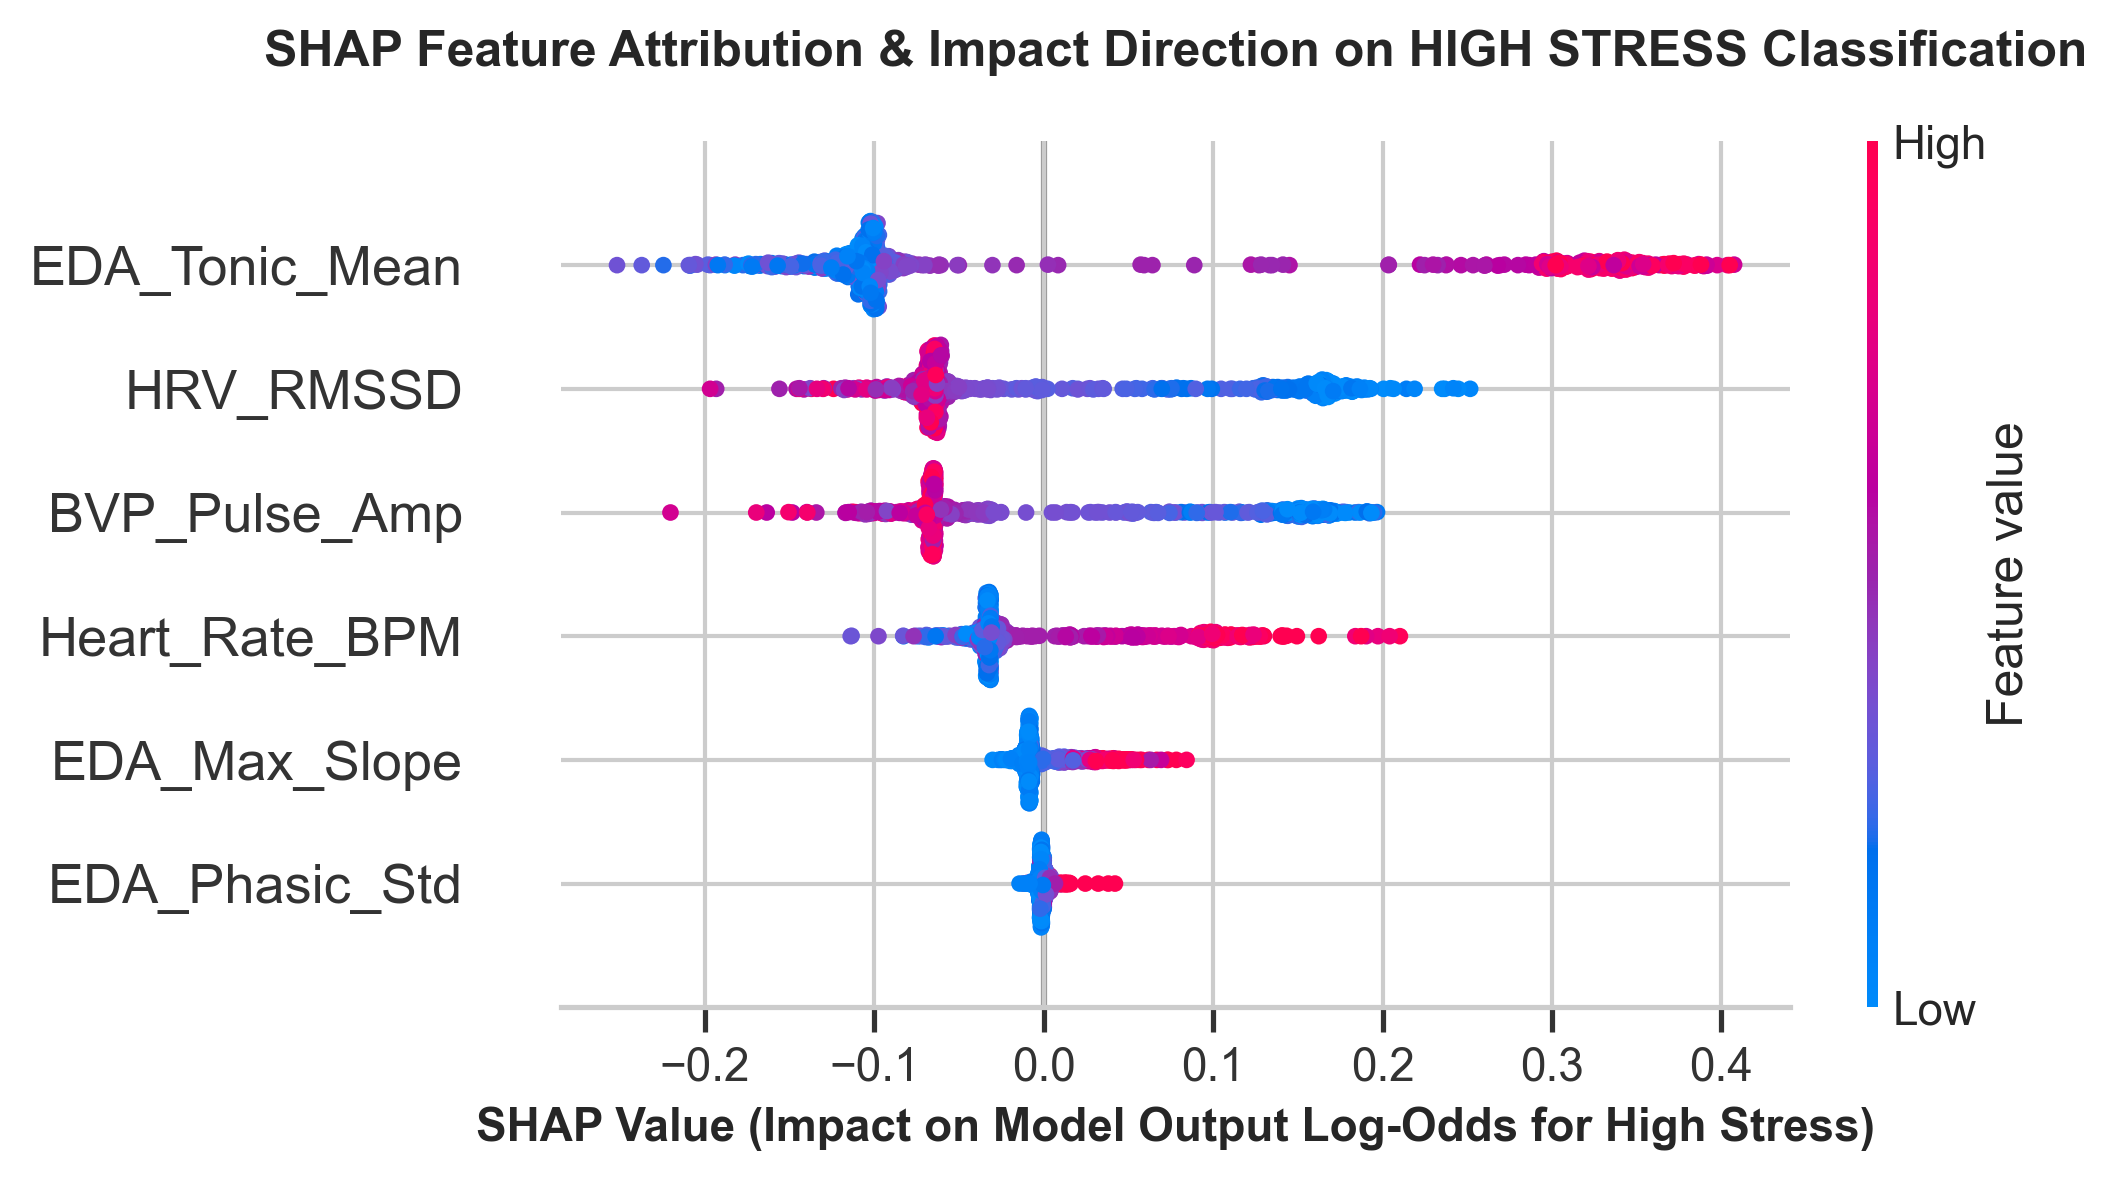

In [5]:
# =============================================================
# FIGURE 7 (ENGLISH VERSION): SHAP Feature Importance & Impact Direction
# =============================================================
plt.figure(figsize=(10.5, 5.8), dpi=300)
shap.summary_plot(sv_high_stress, X_features, show=False)
plt.title("SHAP Feature Attribution & Impact Direction on HIGH STRESS Classification", fontsize=12, fontweight='bold', pad=18)
plt.xlabel("SHAP Value (Impact on Model Output Log-Odds for High Stress)", fontweight='bold', fontsize=11)
plt.subplots_adjust(left=0.28, right=0.92, top=0.88, bottom=0.14)

fig7_en_png = os.path.join(FIG_DIR, 'fig7_shap_summary_beeswarm_en.png')
fig7_en_pdf = os.path.join(FIG_DIR, 'fig7_shap_summary_beeswarm_en.pdf')
plt.savefig(fig7_en_png, dpi=300, bbox_inches='tight')
plt.savefig(fig7_en_pdf, bbox_inches='tight')
print(f"📊 [ENGLISH] Exported Figure 7: {fig7_en_png} & {fig7_en_pdf}")
plt.show()

### 5.3. Hình 8: Giải thích ca lâm sàng cụ thể (Bản Tiếng Việt)

📊 [TIẾNG VIỆT] Đã xuất Hình 8: ../figures\fig8_shap_clinical_waterfall_vi.png & ../figures\fig8_shap_clinical_waterfall_vi.pdf


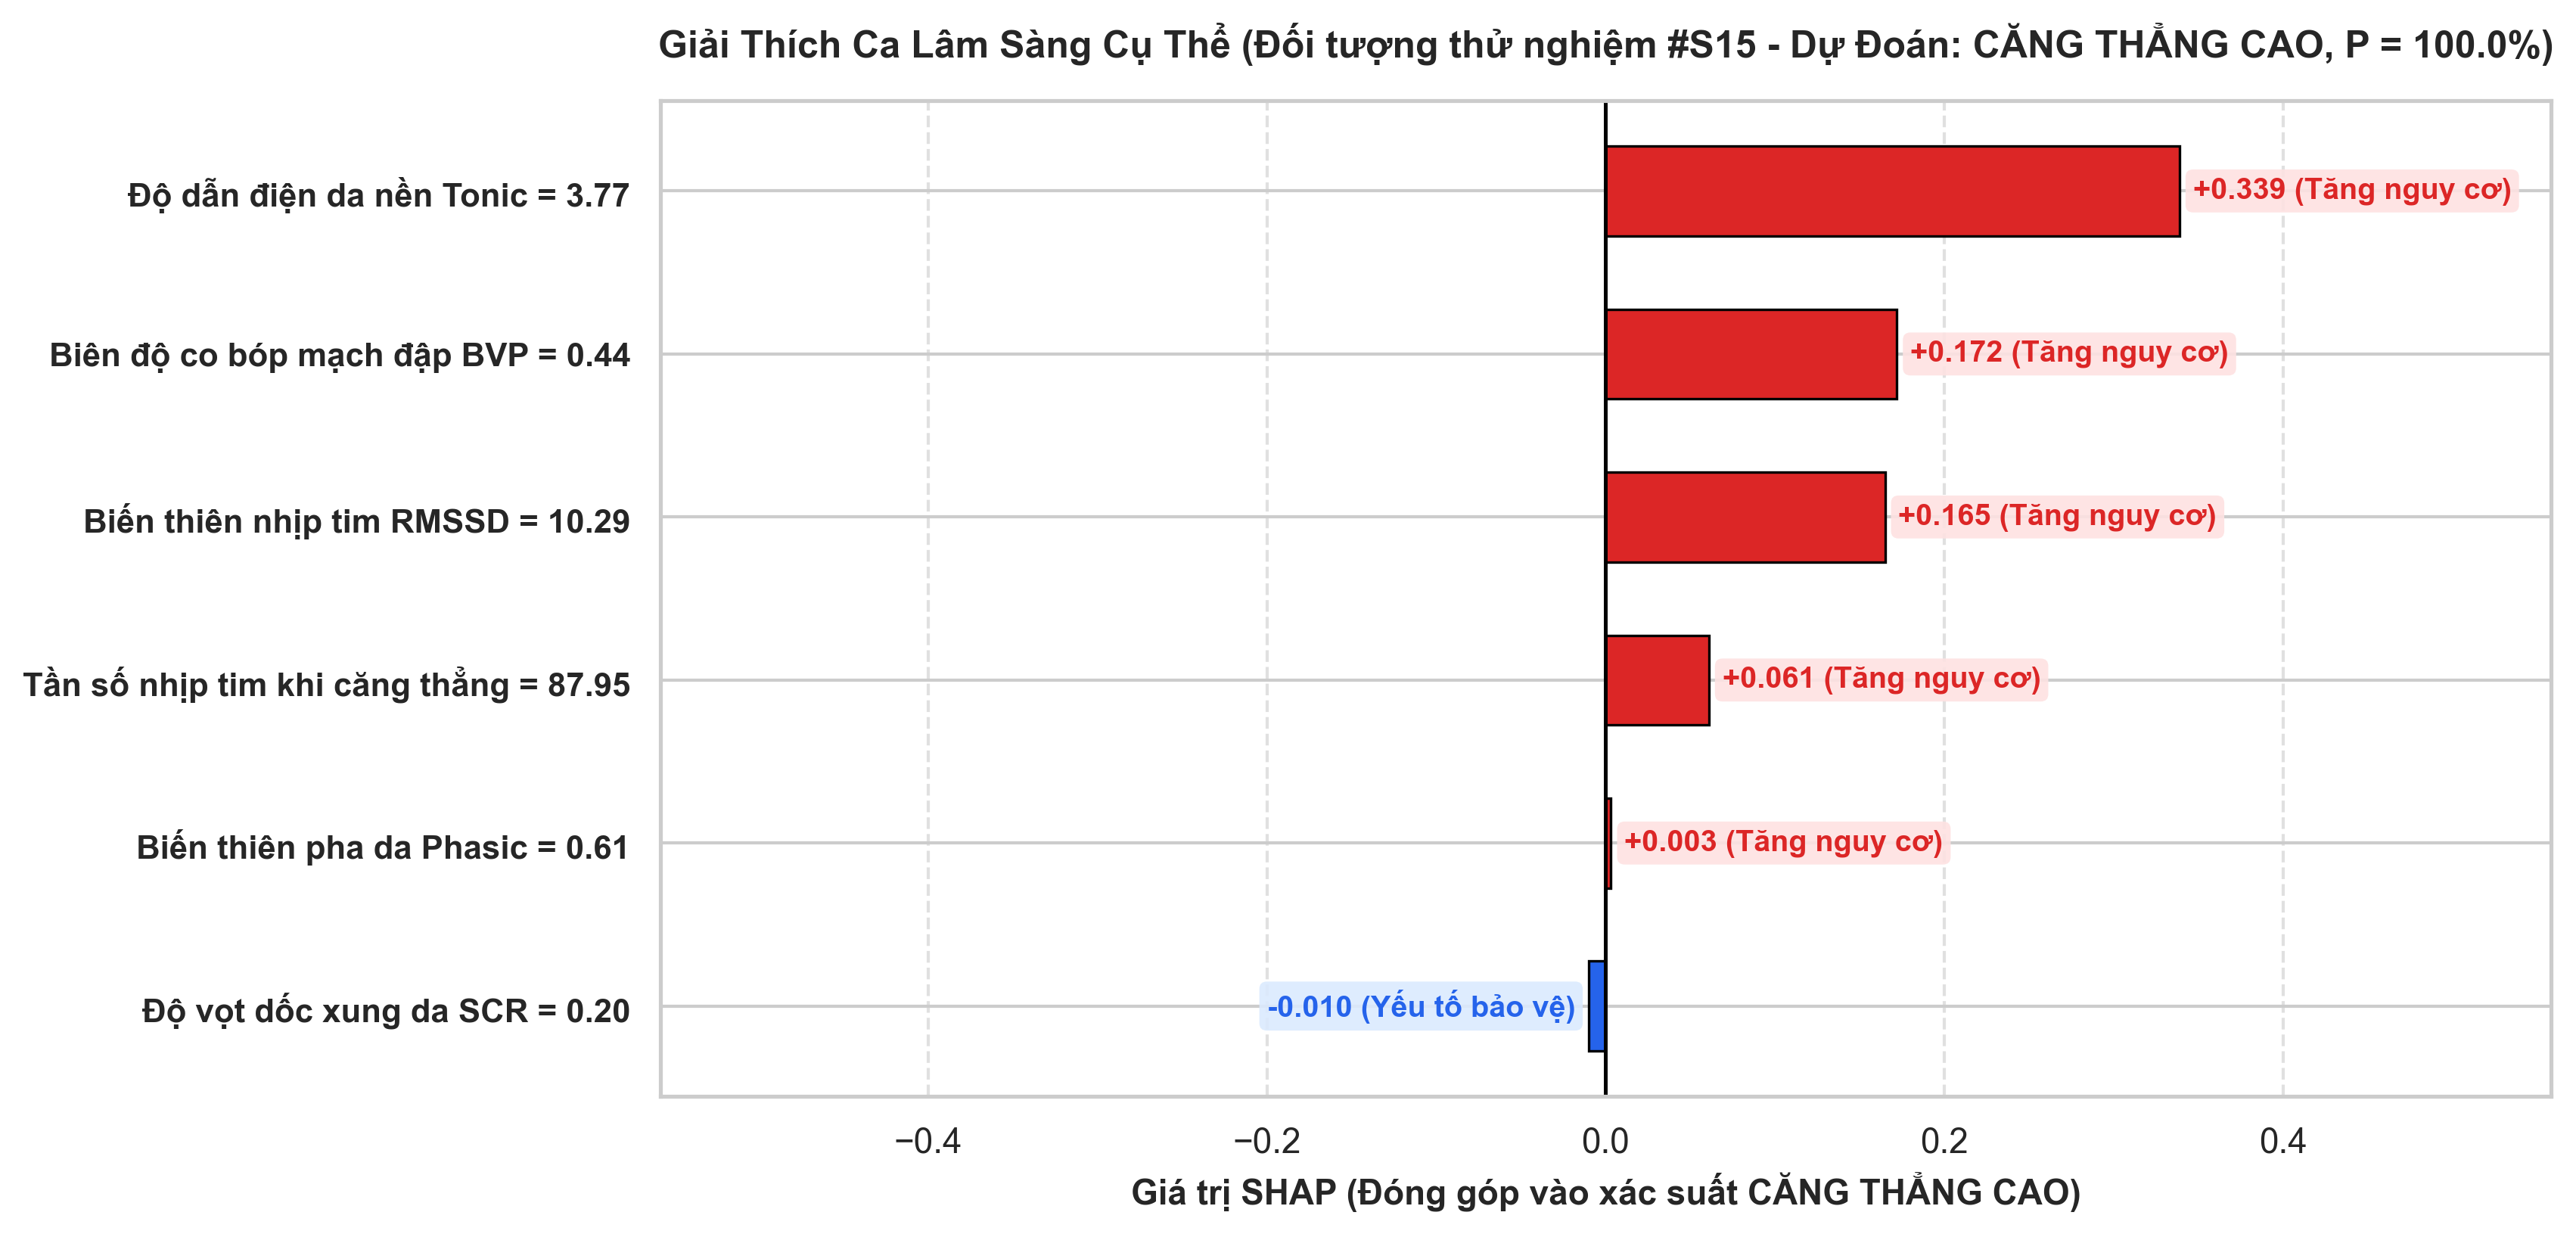

In [6]:
# =============================================================
# HÌNH 8 (BẢN TIẾNG VIỆT): Phân tích ca lâm sàng cụ thể (Đối tượng #S15 Căng thẳng cấp tính)
# =============================================================
probs = rf.predict_proba(X_features)
stress_indices = np.where((y_target == 2) & (probs[:, 2] > 0.85))[0]
target_idx = stress_indices[0]
sample_data = X_features.iloc[target_idx]
pred_prob = probs[target_idx]
sample_shap = sv_high_stress[target_idx]

sort_order = np.argsort(sample_shap)
sorted_features = [X_features.columns[i] for i in sort_order]
sorted_shap = sample_shap[sort_order]
sorted_vals = [sample_data[col] for col in sorted_features]

feature_names_vi_map = {
    'EDA_Tonic_Mean': 'Độ dẫn điện da nền Tonic',
    'HRV_RMSSD': 'Biến thiên nhịp tim RMSSD',
    'Heart_Rate_BPM': 'Tần số nhịp tim khi căng thẳng',
    'EDA_Max_Slope': 'Độ vọt dốc xung da SCR',
    'EDA_Phasic_Std': 'Biến thiên pha da Phasic',
    'BVP_Pulse_Amp': 'Biên độ co bóp mạch đập BVP'
}

fig, ax = plt.subplots(figsize=(11.5, 5.6), dpi=300)
y_pos = np.arange(len(sorted_features))
colors = ['#dc2626' if v > 0 else '#2563eb' for v in sorted_shap]

bars = ax.barh(y_pos, sorted_shap, color=colors, edgecolor='black', linewidth=0.8, height=0.55)
ax.set_yticks(y_pos)
feature_labels_vi = [
    f"{feature_names_vi_map[col]} = {val:.2f}" for col, val in zip(sorted_features, sorted_vals)
]
ax.set_yticklabels(feature_labels_vi, fontweight='bold', fontsize=10.5)
ax.axvline(0, color='black', linewidth=1.2, linestyle='-')

max_abs = max(abs(np.min(sorted_shap)), abs(np.max(sorted_shap)))
ax.set_xlim(-max_abs * 1.5 - 0.05, max_abs * 1.5 + 0.05)
ax.set_xlabel('Giá trị SHAP (Đóng góp vào xác suất CĂNG THẲNG CAO)', fontweight='bold', fontsize=11)
ax.set_title(f'Giải Thích Ca Lâm Sàng Cụ Thể (Đối tượng thử nghiệm #S15 - Dự Đoán: CĂNG THẲNG CAO, P = {pred_prob[2]*100:.1f}%)',
             fontweight='bold', fontsize=12, pad=14)

for bar, val in zip(bars, sorted_shap):
    if val >= 0:
        ax.text(val + 0.008, bar.get_y() + bar.get_height()/2, f"+{val:.3f} (Tăng nguy cơ)",
                va='center', ha='left', color='#dc2626', fontweight='bold', fontsize=9.5,
                bbox=dict(boxstyle='round,pad=0.25', facecolor='#fee2e2', alpha=0.9, edgecolor='none'))
    else:
        ax.text(val - 0.008, bar.get_y() + bar.get_height()/2, f"{val:.3f} (Yếu tố bảo vệ)",
                va='center', ha='right', color='#2563eb', fontweight='bold', fontsize=9.5,
                bbox=dict(boxstyle='round,pad=0.25', facecolor='#dbeafe', alpha=0.9, edgecolor='none'))

ax.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()

fig8_vi_png = os.path.join(FIG_DIR, 'fig8_shap_clinical_waterfall_vi.png')
fig8_vi_pdf = os.path.join(FIG_DIR, 'fig8_shap_clinical_waterfall_vi.pdf')
plt.savefig(fig8_vi_png, dpi=300, bbox_inches='tight')
plt.savefig(fig8_vi_pdf, bbox_inches='tight')
print(f"📊 [TIẾNG VIỆT] Đã xuất Hình 8: {fig8_vi_png} & {fig8_vi_pdf}")
plt.show()

### 5.4. Figure 8: Local Clinical Case Explanation (English Version / IEEE Standard)

📊 [ENGLISH] Exported Figure 8: ../figures\fig8_shap_clinical_waterfall_en.png & ../figures\fig8_shap_clinical_waterfall_en.pdf


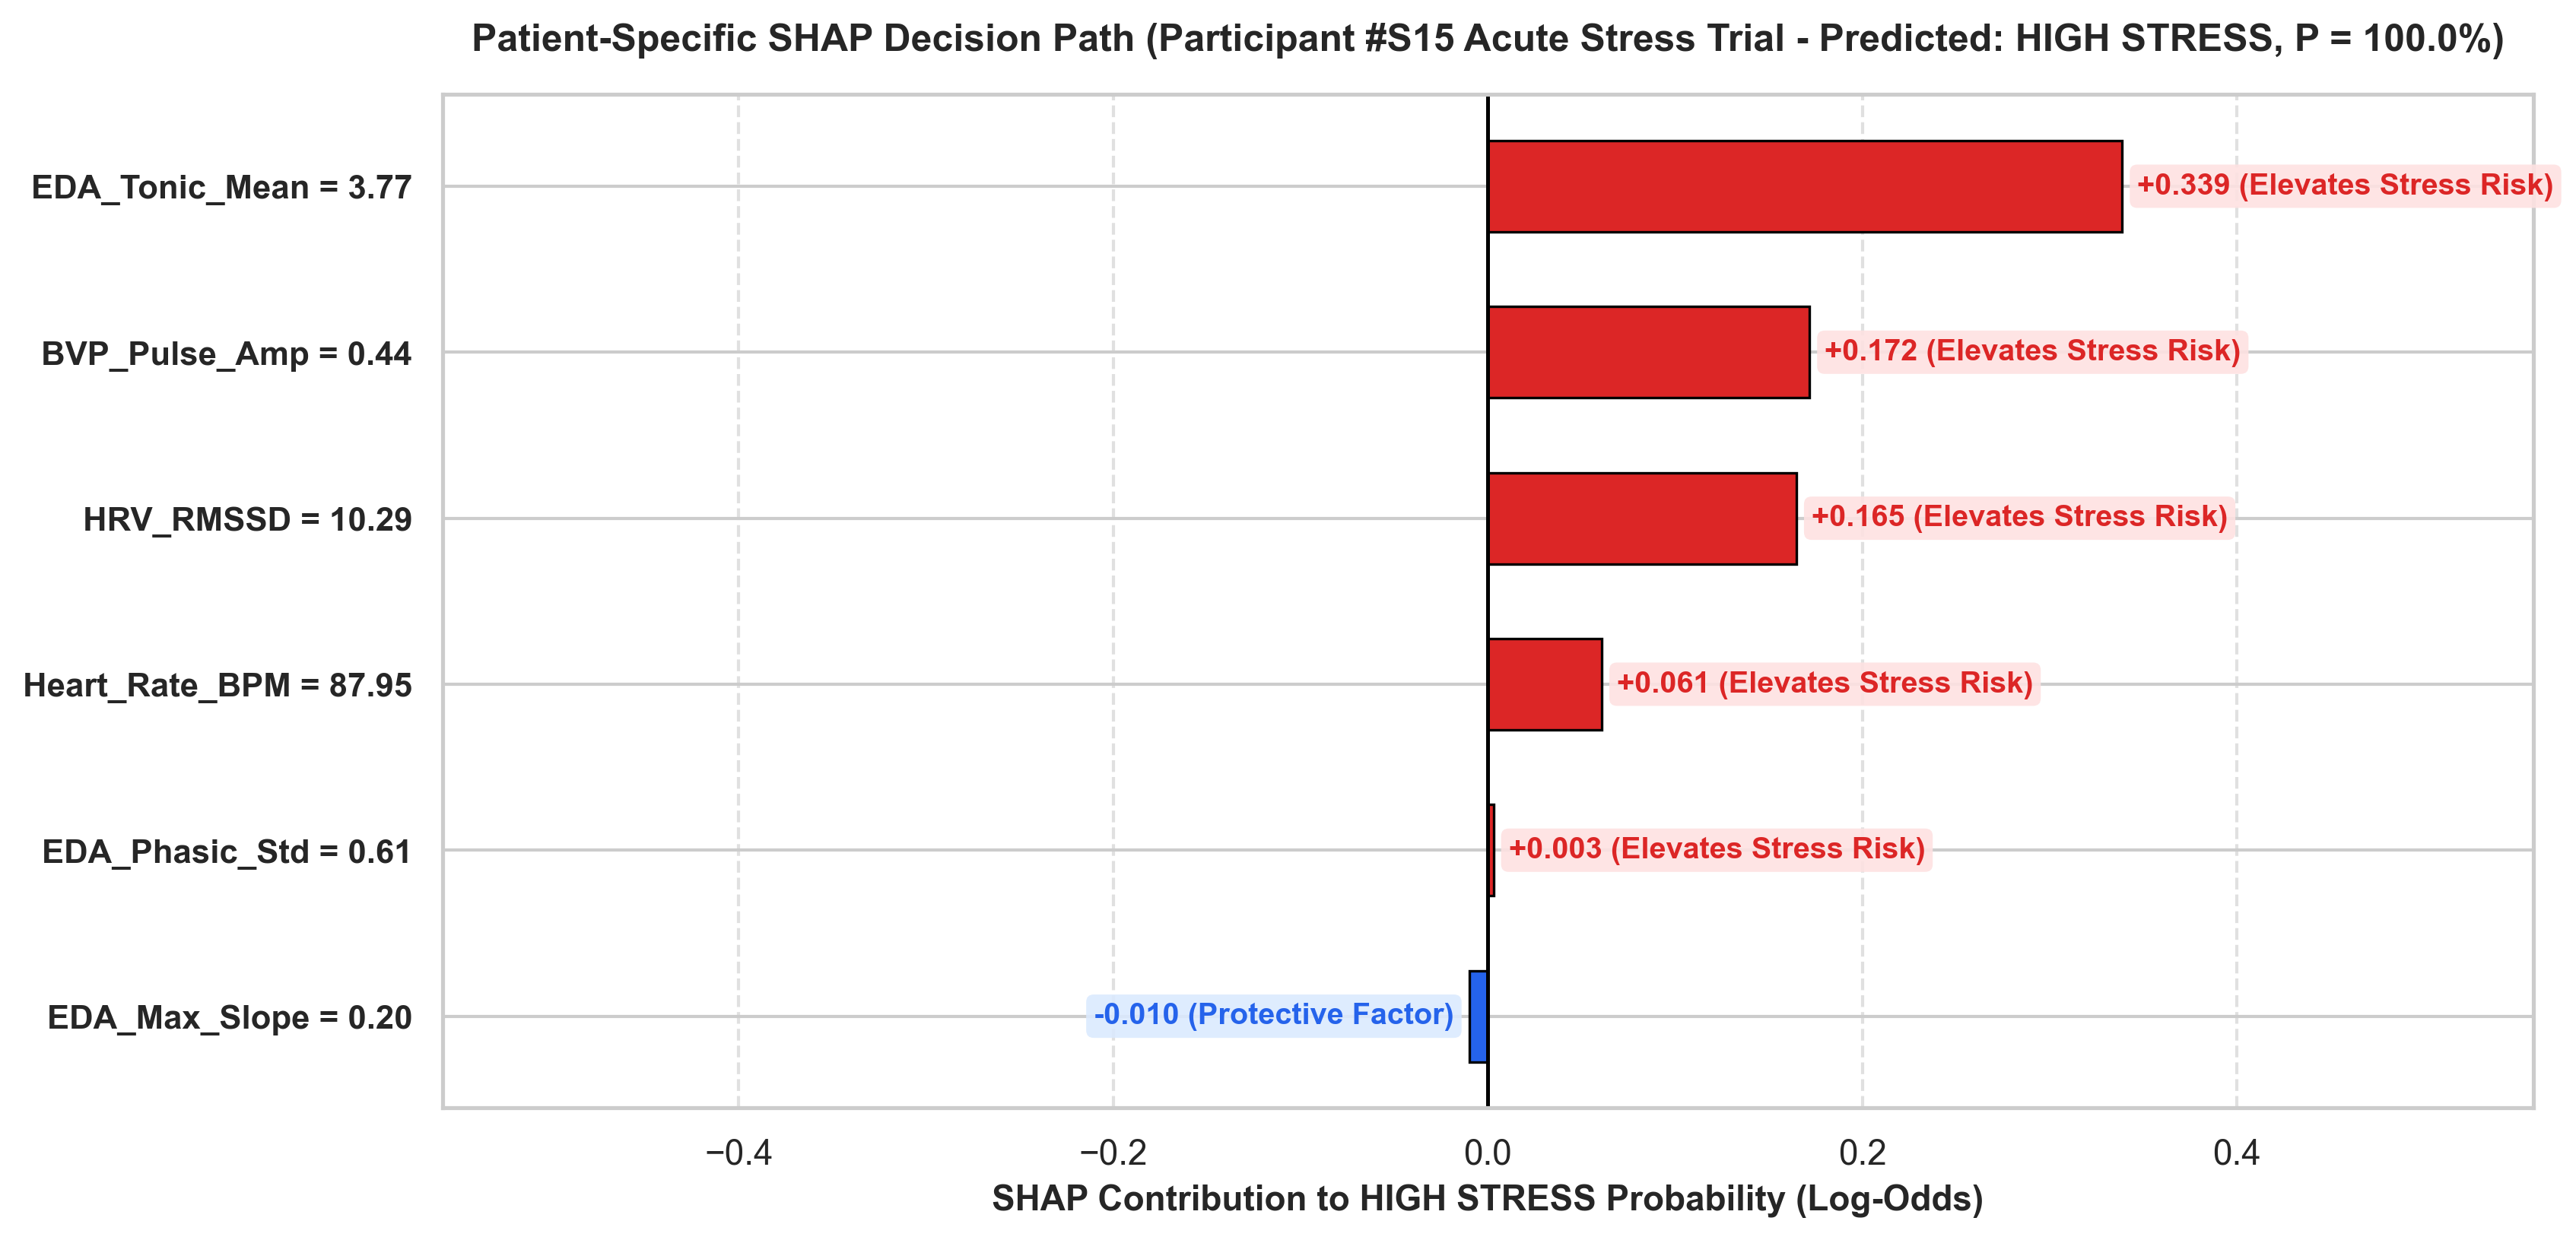

In [7]:
# =============================================================
# FIGURE 8 (ENGLISH VERSION): Local Clinical Case Explanation (Aligned Labels)
# =============================================================
fig, ax = plt.subplots(figsize=(11.5, 5.6), dpi=300)
bars = ax.barh(y_pos, sorted_shap, color=colors, edgecolor='black', linewidth=0.8, height=0.55)
ax.set_yticks(y_pos)
feature_labels_en = [
    f"{col} = {val:.2f}" for col, val in zip(sorted_features, sorted_vals)
]
ax.set_yticklabels(feature_labels_en, fontweight='bold', fontsize=10.5)
ax.axvline(0, color='black', linewidth=1.2, linestyle='-')
ax.set_xlim(-max_abs * 1.5 - 0.05, max_abs * 1.5 + 0.05)

ax.set_xlabel('SHAP Contribution to HIGH STRESS Probability (Log-Odds)', fontweight='bold', fontsize=11)
ax.set_title(f'Patient-Specific SHAP Decision Path (Participant #S15 Acute Stress Trial - Predicted: HIGH STRESS, P = {pred_prob[2]*100:.1f}%)',
             fontweight='bold', fontsize=12, pad=14)

for bar, val in zip(bars, sorted_shap):
    if val >= 0:
        ax.text(val + 0.008, bar.get_y() + bar.get_height()/2, f"+{val:.3f} (Elevates Stress Risk)",
                va='center', ha='left', color='#dc2626', fontweight='bold', fontsize=9.5,
                bbox=dict(boxstyle='round,pad=0.25', facecolor='#fee2e2', alpha=0.9, edgecolor='none'))
    else:
        ax.text(val - 0.008, bar.get_y() + bar.get_height()/2, f"{val:.3f} (Protective Factor)",
                va='center', ha='right', color='#2563eb', fontweight='bold', fontsize=9.5,
                bbox=dict(boxstyle='round,pad=0.25', facecolor='#dbeafe', alpha=0.9, edgecolor='none'))

ax.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()

fig8_en_png = os.path.join(FIG_DIR, 'fig8_shap_clinical_waterfall_en.png')
fig8_en_pdf = os.path.join(FIG_DIR, 'fig8_shap_clinical_waterfall_en.pdf')
plt.savefig(fig8_en_png, dpi=300, bbox_inches='tight')
plt.savefig(fig8_en_pdf, bbox_inches='tight')
print(f"📊 [ENGLISH] Exported Figure 8: {fig8_en_png} & {fig8_en_pdf}")
plt.show()

### 5.5. Hình 9: Ma trận chiến lược phân bổ bài tập can thiệp (Bản Tiếng Việt)

📊 [TIẾNG VIỆT] Đã xuất Hình 9: ../figures\fig9_recommendation_strategy_matrix_vi.png & ../figures\fig9_recommendation_strategy_matrix_vi.pdf


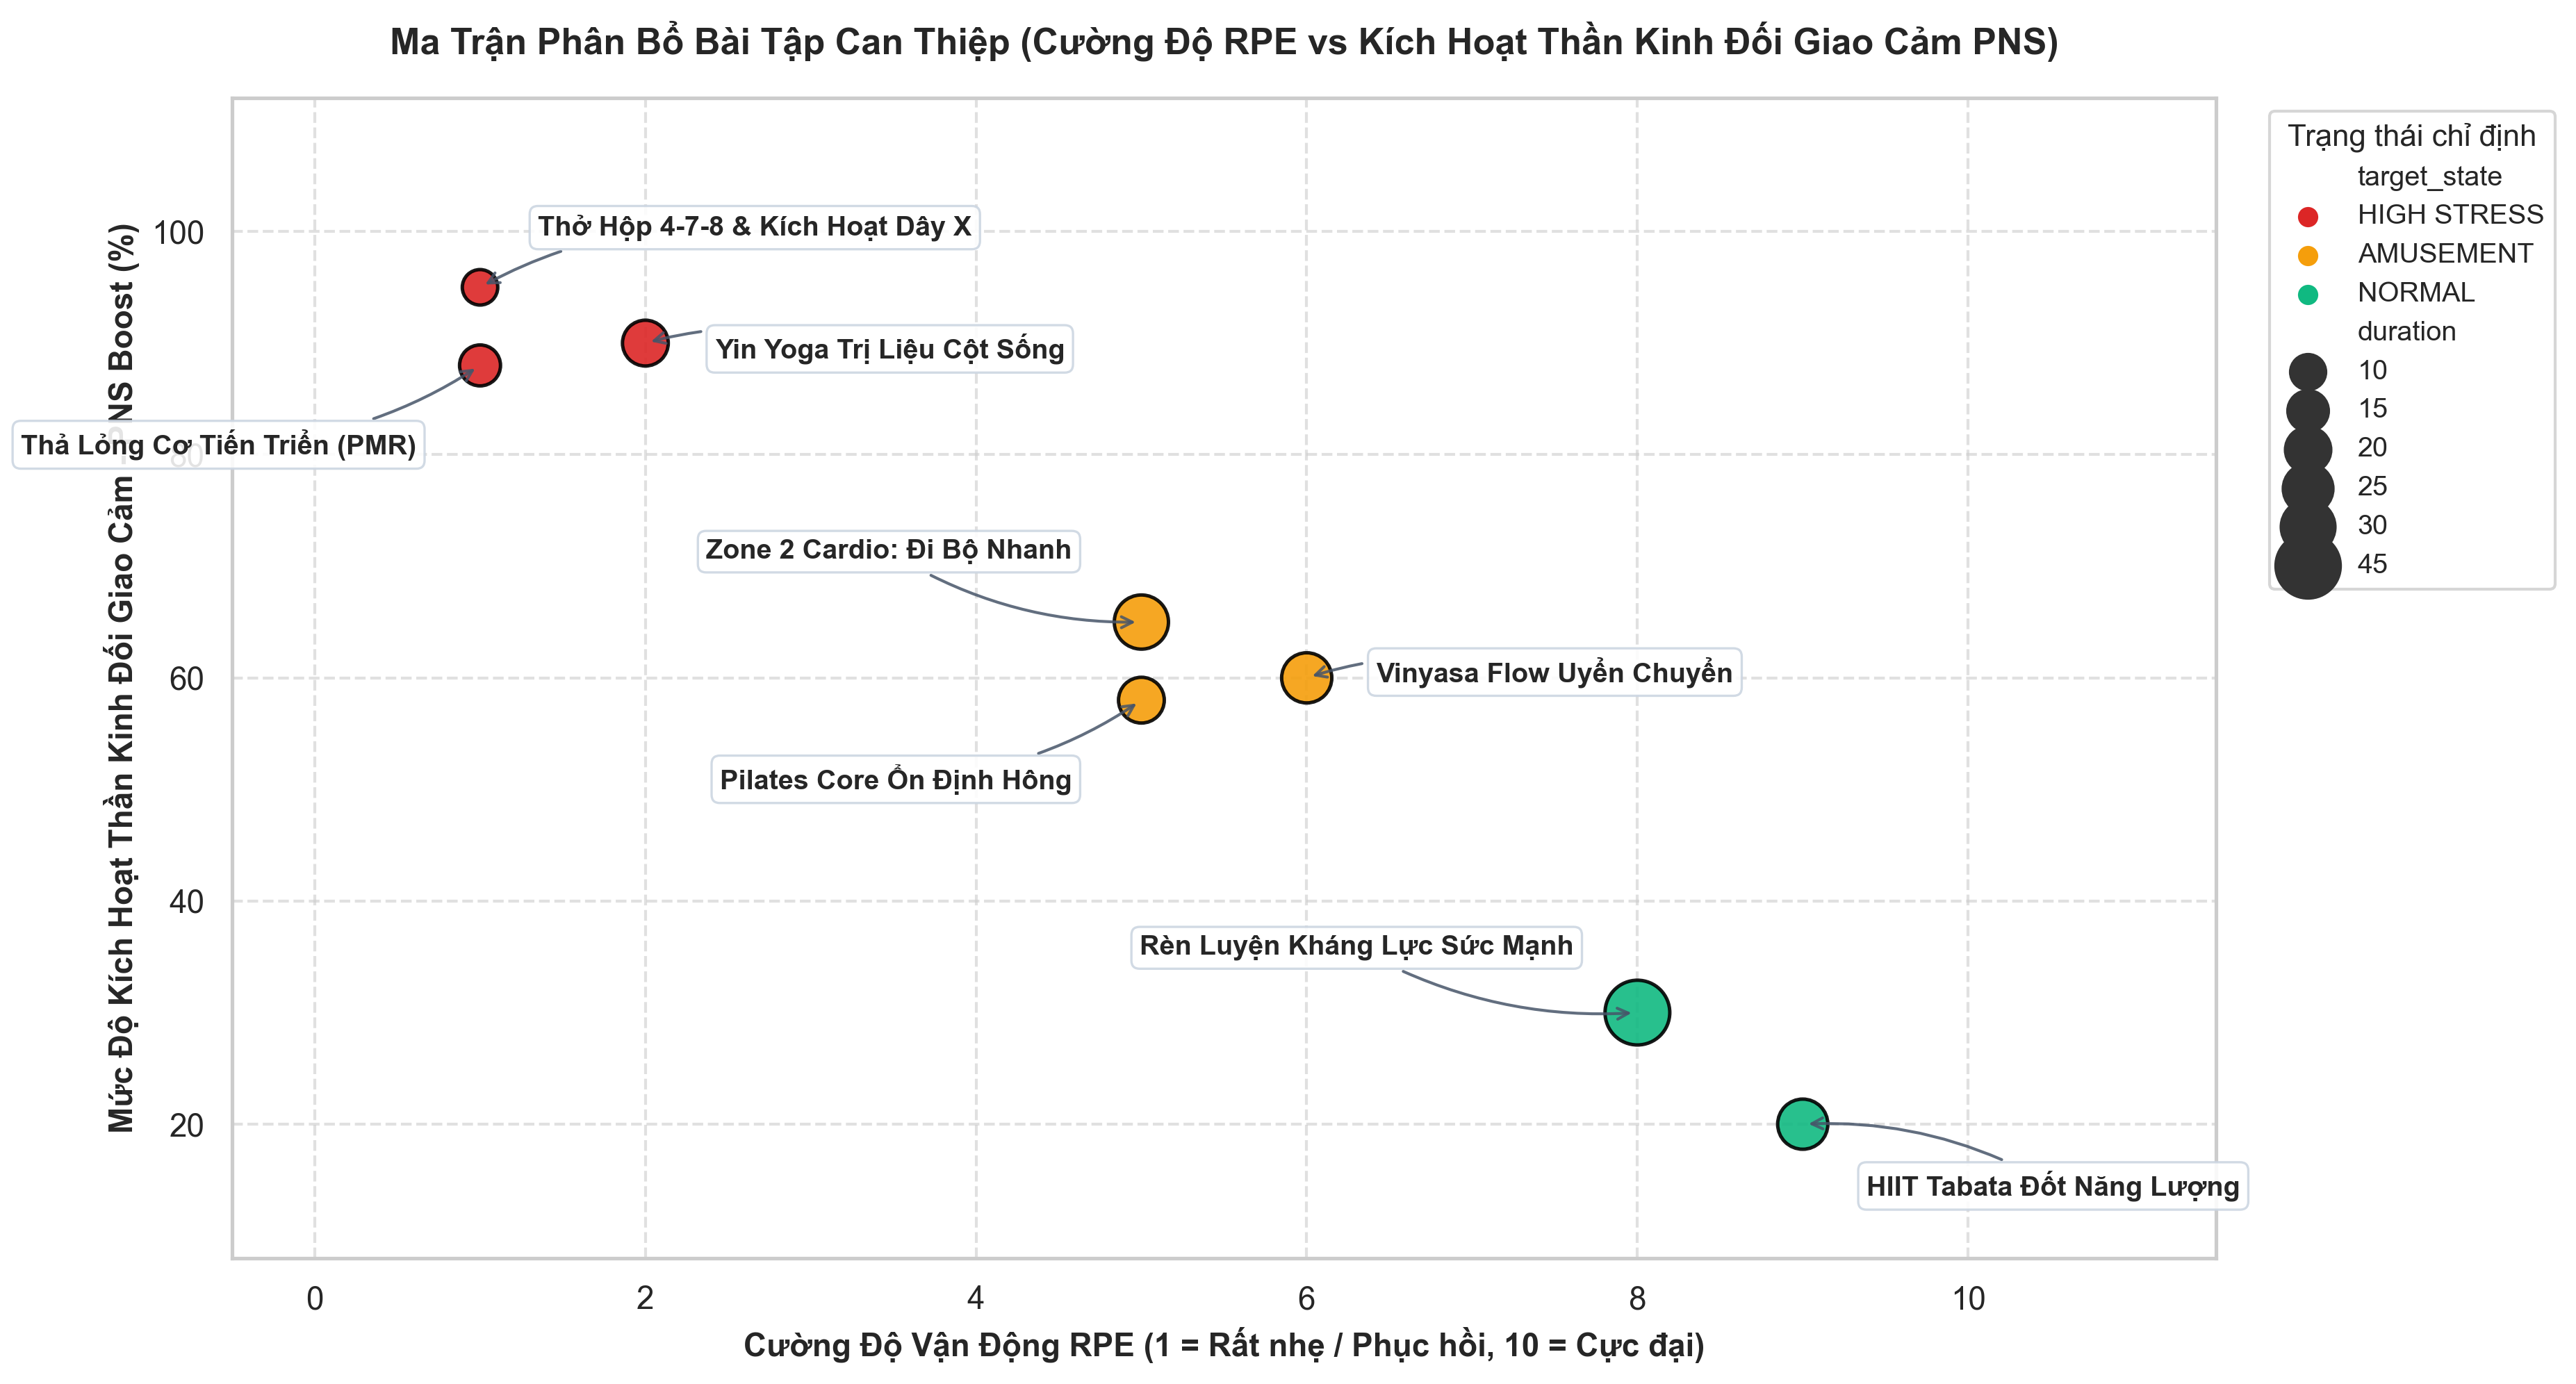

In [8]:
# =============================================================
# HÌNH 9 (BẢN TIẾNG VIỆT): Ma trận phân bổ bài tập can thiệp (Chống đè chữ thông minh)
# =============================================================
fig, ax = plt.subplots(figsize=(12.5, 6.8), dpi=300)
palette = {'HIGH STRESS': '#dc2626', 'AMUSEMENT': '#f59e0b', 'NORMAL': '#10b981'}

scatter = sns.scatterplot(
    data=df_exercises,
    x='intensity',
    y='pns_boost',
    size='duration',
    hue='target_state',
    palette=palette,
    sizes=(150, 500),
    alpha=0.9,
    edgecolor='black',
    linewidth=1.2,
    ax=ax
)

# Bản đồ dịch chuyển nhãn (Offset & Alignment) riêng biệt cho từng bài tập để không bao giờ đè lên nhau
label_offsets_vi = {
    'ex_001': {'xytext': (20, 16), 'ha': 'left', 'va': 'bottom'},
    'ex_002': {'xytext': (24, -2), 'ha': 'left', 'va': 'center'},
    'ex_003': {'xytext': (-22, -22), 'ha': 'right', 'va': 'top'},
    'ex_004': {'xytext': (-24, 20), 'ha': 'right', 'va': 'bottom'},
    'ex_005': {'xytext': (24, 2), 'ha': 'left', 'va': 'center'},
    'ex_006': {'xytext': (-24, -22), 'ha': 'right', 'va': 'top'},
    'ex_007': {'xytext': (22, -16), 'ha': 'left', 'va': 'top'},
    'ex_008': {'xytext': (-22, 18), 'ha': 'right', 'va': 'bottom'}
}

for _, row in df_exercises.iterrows():
    eid = row['id']
    cfg = label_offsets_vi.get(eid, {'xytext': (0, 15), 'ha': 'center', 'va': 'bottom'})
    ax.annotate(
        row['name_vi'],
        (row['intensity'], row['pns_boost']),
        xytext=cfg['xytext'],
        textcoords='offset points',
        ha=cfg['ha'],
        va=cfg['va'],
        fontsize=9.5,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.88, edgecolor='#cbd5e1', lw=0.8),
        arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.15', color='#475569', lw=1.0, alpha=0.85)
    )

ax.set_title('Ma Trận Phân Bổ Bài Tập Can Thiệp (Cường Độ RPE vs Kích Hoạt Thần Kinh Đối Giao Cảm PNS)',
             fontweight='bold', fontsize=12.5, pad=15)
ax.set_xlabel('Cường Độ Vận Động RPE (1 = Rất nhẹ / Phục hồi, 10 = Cực đại)', fontweight='bold', fontsize=11)
ax.set_ylabel('Mức Độ Kích Hoạt Thần Kinh Đối Giao Cảm - PNS Boost (%)', fontweight='bold', fontsize=11)
ax.set_xlim(-0.5, 11.5)
ax.set_ylim(8, 112)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, title='Trạng thái chỉ định', fontsize=9.5, title_fontsize=10.5)

plt.tight_layout()
fig9_vi_png = os.path.join(FIG_DIR, 'fig9_recommendation_strategy_matrix_vi.png')
fig9_vi_pdf = os.path.join(FIG_DIR, 'fig9_recommendation_strategy_matrix_vi.pdf')
plt.savefig(fig9_vi_png, dpi=300, bbox_inches='tight')
plt.savefig(fig9_vi_pdf, bbox_inches='tight')
print(f"📊 [TIẾNG VIỆT] Đã xuất Hình 9: {fig9_vi_png} & {fig9_vi_pdf}")
plt.show()

### 5.6. Figure 9: Exercise Allocation Strategy Matrix (English Version / IEEE Standard)

📊 [ENGLISH] Exported Figure 9: ../figures\fig9_recommendation_strategy_matrix_en.png & ../figures\fig9_recommendation_strategy_matrix_en.pdf


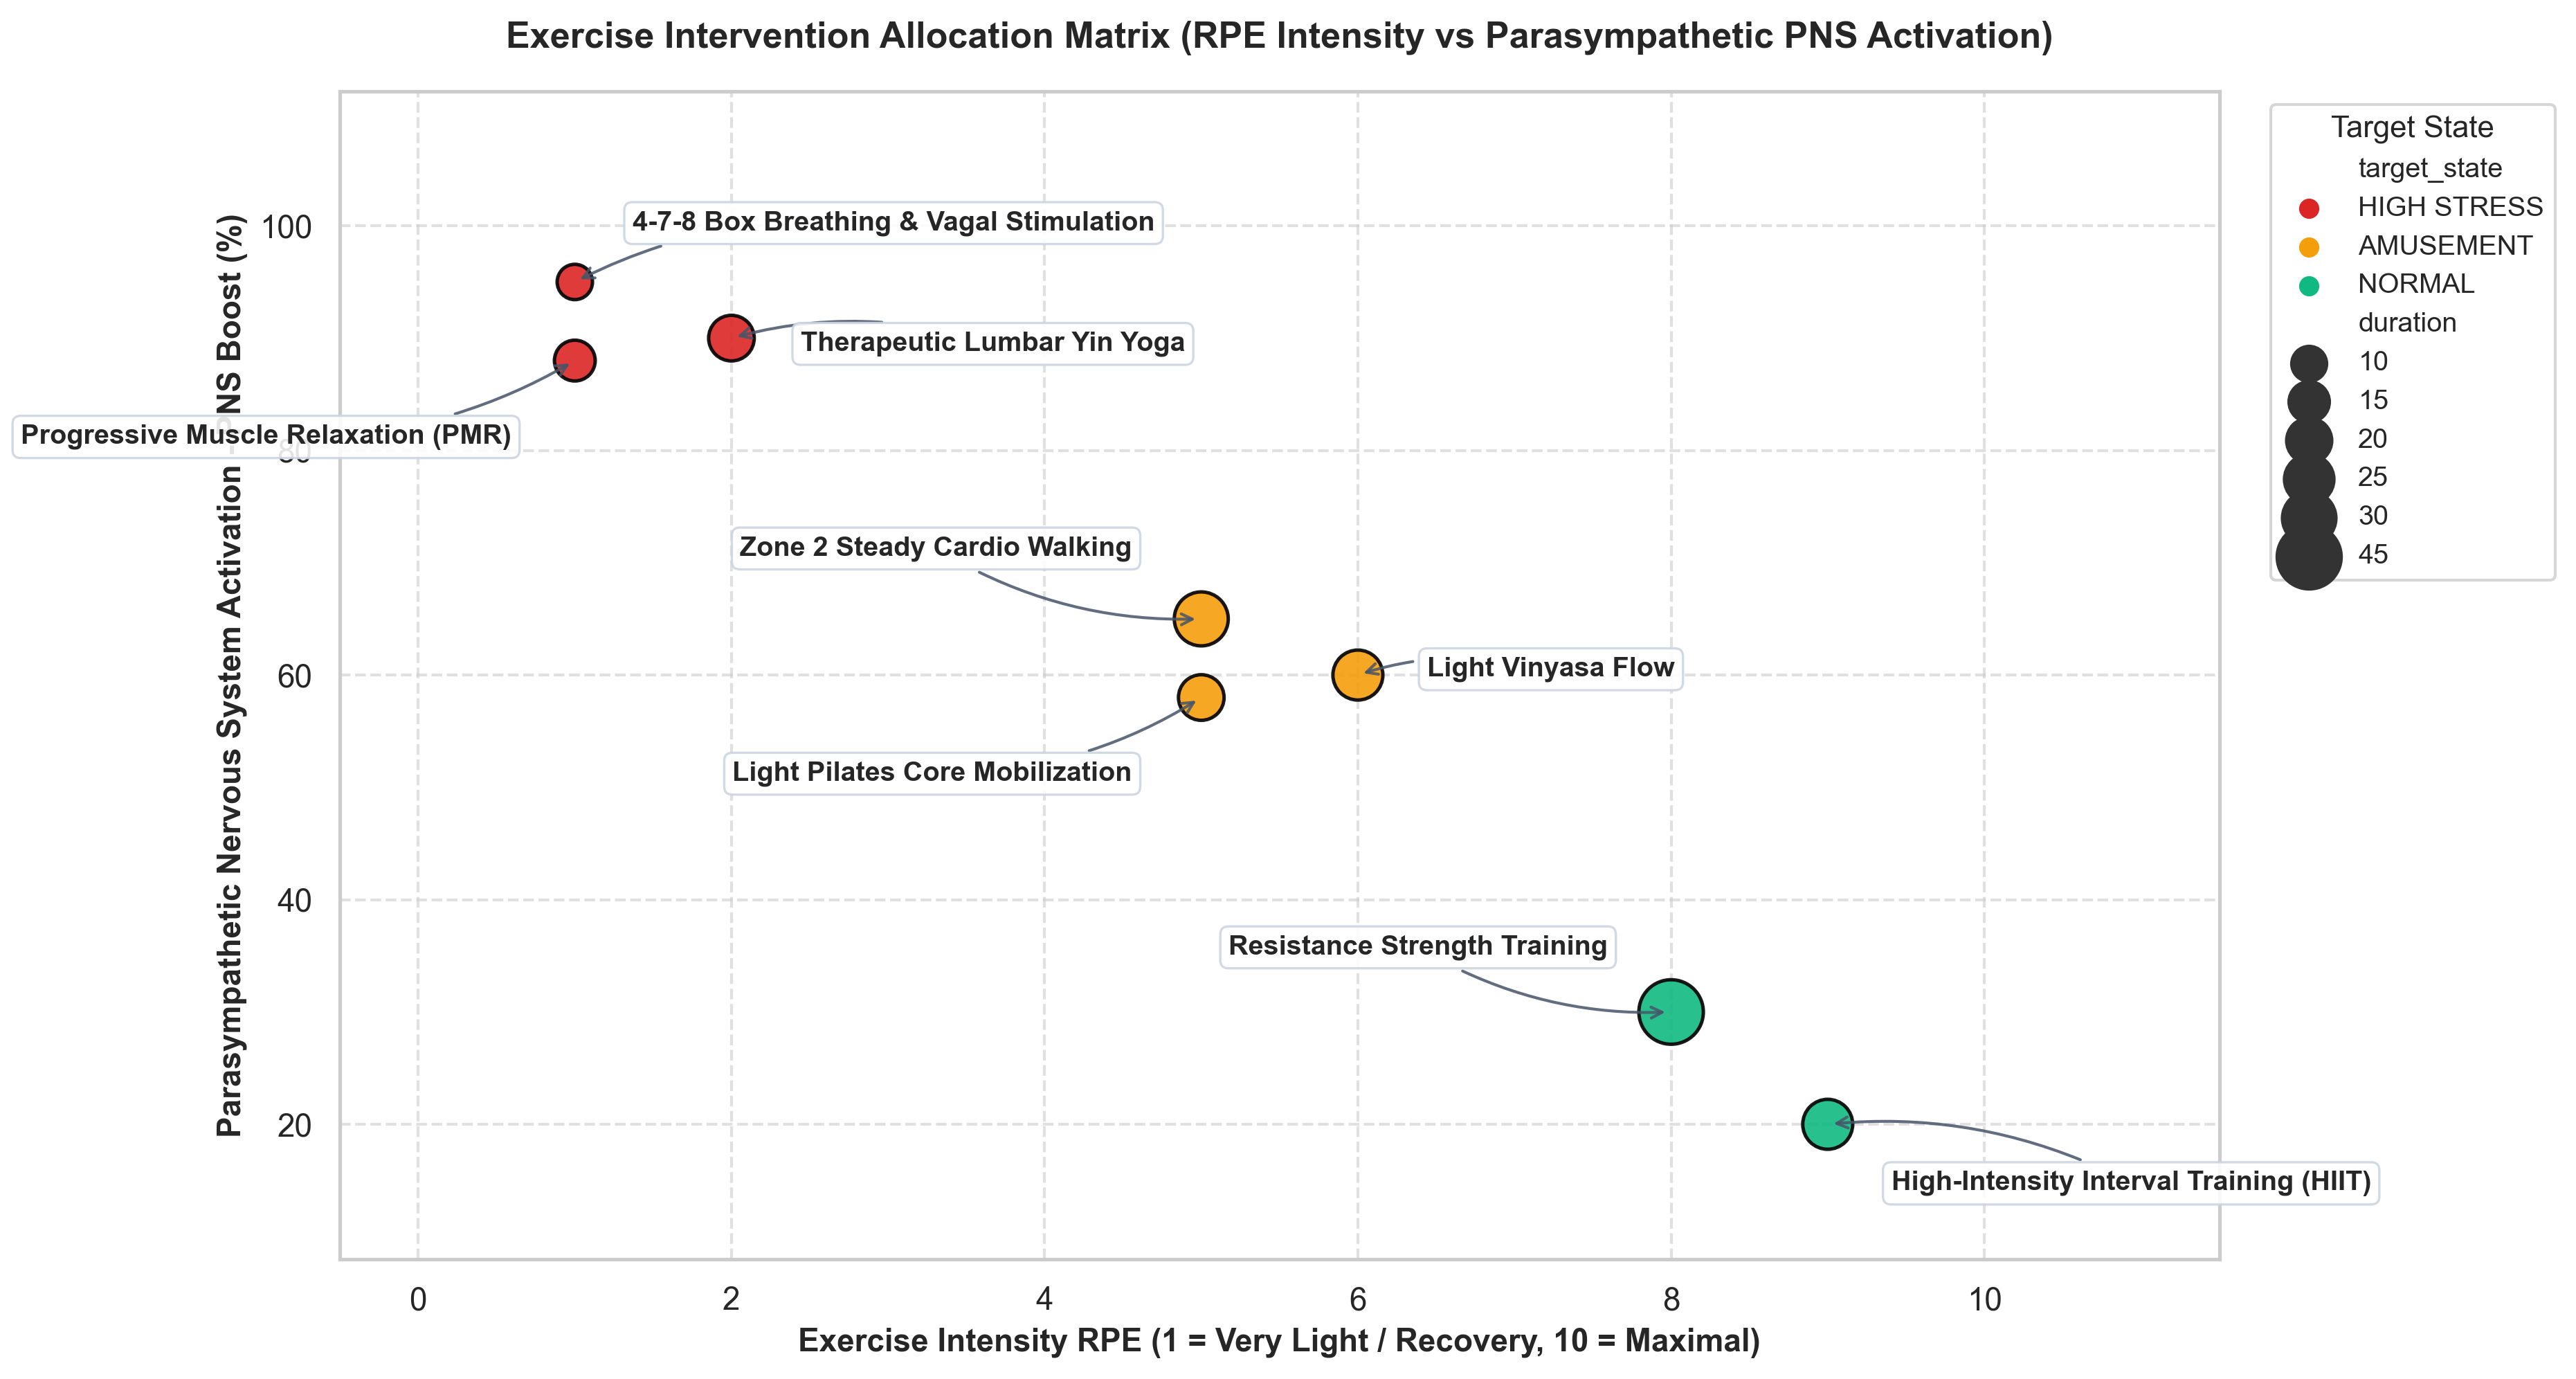

In [9]:
# =============================================================
# FIGURE 9 (ENGLISH VERSION): Exercise Allocation Strategy Matrix (Smart Aligned)
# =============================================================
fig, ax = plt.subplots(figsize=(12.5, 6.8), dpi=300)

scatter = sns.scatterplot(
    data=df_exercises,
    x='intensity',
    y='pns_boost',
    size='duration',
    hue='target_state',
    palette=palette,
    sizes=(150, 500),
    alpha=0.9,
    edgecolor='black',
    linewidth=1.2,
    ax=ax
)

for _, row in df_exercises.iterrows():
    eid = row['id']
    cfg = label_offsets_vi.get(eid, {'xytext': (0, 15), 'ha': 'center', 'va': 'bottom'})
    ax.annotate(
        row['name_en'],
        (row['intensity'], row['pns_boost']),
        xytext=cfg['xytext'],
        textcoords='offset points',
        ha=cfg['ha'],
        va=cfg['va'],
        fontsize=9.5,
        fontweight='bold',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.88, edgecolor='#cbd5e1', lw=0.8),
        arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=0.15', color='#475569', lw=1.0, alpha=0.85)
    )

ax.set_title('Exercise Intervention Allocation Matrix (RPE Intensity vs Parasympathetic PNS Activation)',
             fontweight='bold', fontsize=12.5, pad=15)
ax.set_xlabel('Exercise Intensity RPE (1 = Very Light / Recovery, 10 = Maximal)', fontweight='bold', fontsize=11)
ax.set_ylabel('Parasympathetic Nervous System Activation - PNS Boost (%)', fontweight='bold', fontsize=11)
ax.set_xlim(-0.5, 11.5)
ax.set_ylim(8, 112)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True, title='Target State', fontsize=9.5, title_fontsize=10.5)

plt.tight_layout()
fig9_en_png = os.path.join(FIG_DIR, 'fig9_recommendation_strategy_matrix_en.png')
fig9_en_pdf = os.path.join(FIG_DIR, 'fig9_recommendation_strategy_matrix_en.pdf')
plt.savefig(fig9_en_png, dpi=300, bbox_inches='tight')
plt.savefig(fig9_en_pdf, bbox_inches='tight')
print(f"📊 [ENGLISH] Exported Figure 9: {fig9_en_png} & {fig9_en_pdf}")
plt.show()

## 4. Hoàn Thành Pipeline Huấn Luyện & Xuất Báo Cáo
Toàn bộ 9 cặp biểu đồ học thuật chuẩn IEEE / Science (DPI 300, Song ngữ VI / EN) đã được kết xuất vào thư mục `figures/` để chèn vào báo cáo NCKH / Slide thuyết trình.